# Image enhancement

**Experiment with the following tasks for image enhancement:**

- Segmentation utilizing the color information (Lab color model)
    - Make sure your Lab conversion is in correct data range
    - Select the small part of the image containing only nuclei and compute its Lab color model (target) - average L / a / b values
    - Compute delta Lab - difference image between the input and the target
        - Hint how to compute difference in the slides from lecture
        - Visualize
    - Use the obtained difference image and try to segment nuclei by thresholding
- Use your knowledge of local descriptors to detect and localize image patch within the larger image from following data - [link](https://drive.google.com/file/u/2/d/10oNHED7BGrcYomKd3Cn5J1ZKQuQ9TR5d/view?usp=sharing)
    - Experiment with feature detectors: SIFT, FAST, Harris
    - Experiment with feature descriptors: SIFT, SURF, ORB
    - Compute homography matrix and localize your image patch
    - Find the best combination of detection & description for your task



In [25]:
import cv2 as cv
import matplotlib.pyplot as plt
import numpy as np

### Segmentation utilizing the color information

### Feature matching with detectors and descriptors

In [26]:
# Load the two images
lookup_img = cv.imread('images/descriptors/lookup.tif')
patch_img = cv.imread('images/descriptors/patch1.tif')

# Convert to grayscale
gray1 = cv.cvtColor(lookup_img, cv.COLOR_BGR2GRAY)
gray2 = cv.cvtColor(patch_img, cv.COLOR_BGR2GRAY)

#### SIFT

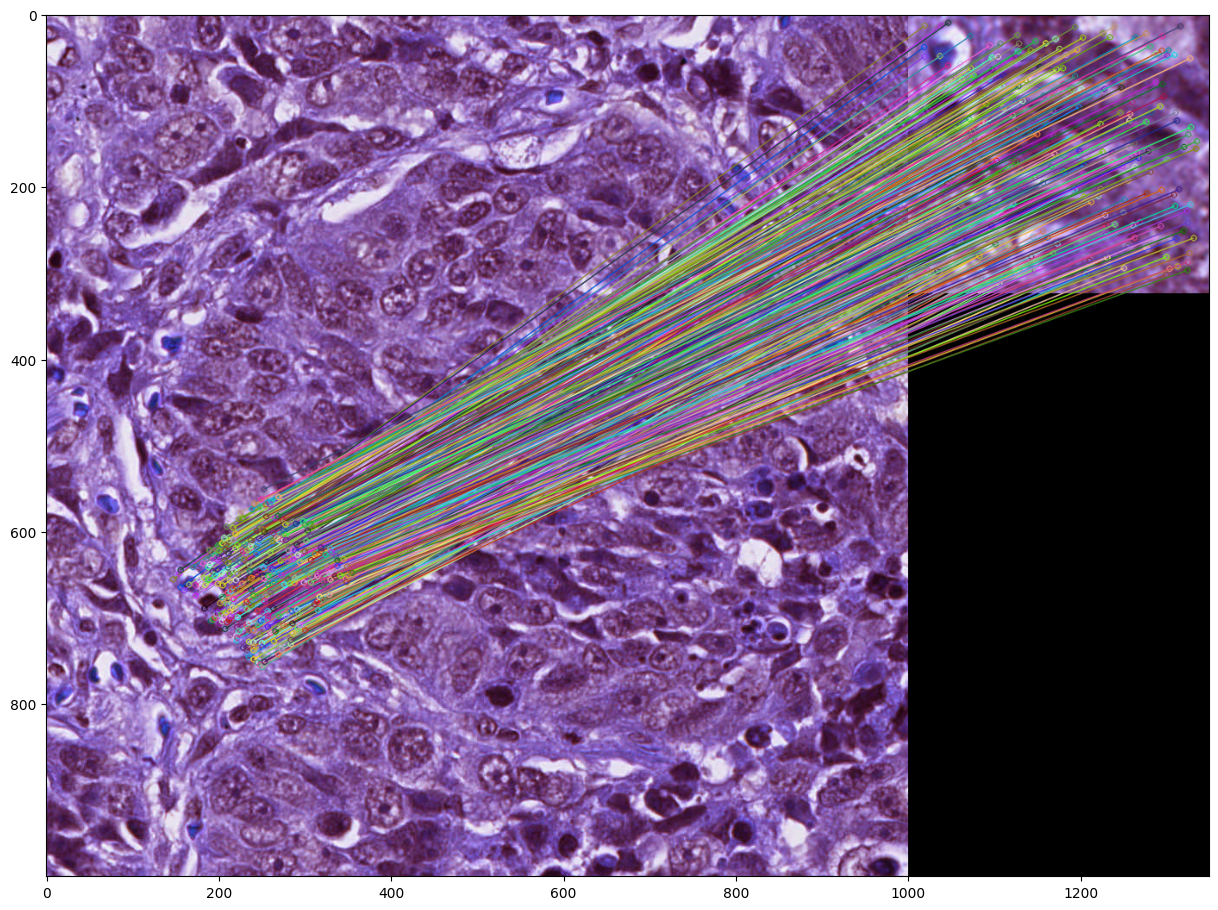

In [27]:
# Create SIFT detector
sift = cv.xfeatures2d.SIFT_create()

# Find keypoints and descriptors
kp1, des1 = sift.detectAndCompute(gray1, None)
kp2, des2 = sift.detectAndCompute(gray2, None)

# Match descriptors between images
matcher = cv.DescriptorMatcher_create(cv.DescriptorMatcher_FLANNBASED)
knn_matches = matcher.knnMatch(des1, des2, k=2)

# Filter matches using the Lowe's ratio test
ratio_thresh = 0.5
good_matches = []
for m, n in knn_matches:
    if m.distance < ratio_thresh * n.distance:
        good_matches.append(m)

# Draw matches
img_matches = np.empty((max(lookup_img.shape[0], patch_img.shape[0]), lookup_img.shape[1] + patch_img.shape[1], 3), dtype=np.uint8)
cv.drawMatches(lookup_img, kp1, patch_img, kp2, good_matches, img_matches, flags=cv.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS)

# Plot the matches
plt.figure(figsize=(15, 15))
plt.imshow(img_matches)
plt.show()

# Show detected matches
cv.imshow('Good Matches', img_matches)
cv.waitKey(0)
cv.destroyAllWindows()

#### ORB

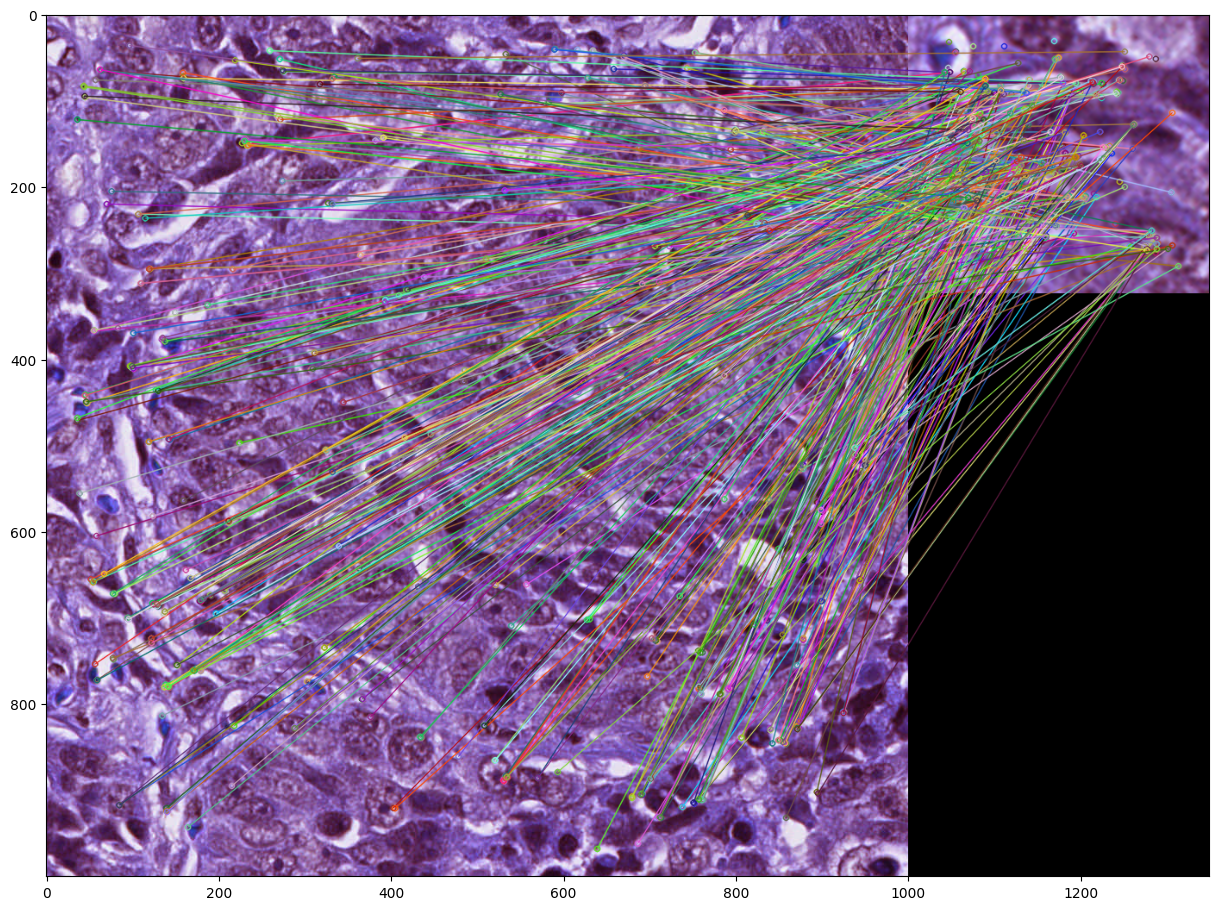

In [28]:
# Create a detector
orb = cv.ORB_create()

# Find keypoints and descriptors
kp1, des1 = orb.detectAndCompute(gray1, None)
kp2, des2 = orb.detectAndCompute(gray2, None)

# Match descriptors between images
matcher = cv.DescriptorMatcher_create(cv.DescriptorMatcher_BRUTEFORCE_HAMMING)

# Match descriptors
matches = matcher.match(des1, des2, None)

# Sort matches by score
matches = sorted(matches, key=lambda x: x.distance)

# Remove not so good matches
# num_good_matches = 100
# matches = matches[:num_good_matches]

# Draw top matches
img_matches = cv.drawMatches(lookup_img, kp1, patch_img, kp2, matches, None)

# Plot the matches
plt.figure(figsize=(15, 15))
plt.imshow(img_matches)
plt.show()

# Show detected matches
cv.imshow('Good Matches', img_matches)
cv.waitKey(0)
cv.destroyAllWindows()